# Uji Validitas dan Reliabilitas Instrumen
Kelas **3 TI C** | Dua kelompok data: **Penggunaan AI** dan **Aspek Psikologis** | Skala Likert konversi positif (STJ=1 sampai SS=5)

## Langkah 1: Impor pustaka

In [1]:
import re
import warnings
import pandas as pd
import numpy as np
from scipy import stats

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
# butir yang semua jawabannya sama (varians nol) menghasilkan peringatan saat sampel kecil
warnings.filterwarnings("ignore", category=RuntimeWarning)
print("Colab:", IN_COLAB)

Colab: False


## Langkah 2: Unggah berkas

In [2]:
if IN_COLAB:
    up = files.upload()
    nama_file = list(up.keys())[0]
else:
    nama_file = "Blank_Quiz_Responses_3_TIC_2.xlsx"   # berkas diletakkan satu folder dengan notebook
print("File terbaca:", nama_file)

File terbaca: Blank_Quiz_Responses_3_TIC_2.xlsx


## Langkah 3: Baca data, filter kelas 3 TI C, lalu hapus Timestamp, Score, dan Kelas

In [3]:
df_awal = pd.read_excel(nama_file)
print("Total responden semua kelas:", len(df_awal))
print(df_awal["Kelas"].value_counts(), "\n")

# filter dulu, baru kolom Kelas dibuang
df = df_awal[df_awal["Kelas"].str.strip() == "3 TI C"].copy()

# Timestamp = waktu pengisian, Score = skor bawaan Google Forms (jika ada, tidak bermakna)
df = df.drop(columns=["Timestamp", "Score", "Kelas"], errors="ignore").reset_index(drop=True)
print("Responden 3 TI C :", len(df))
print("Jumlah kolom     :", df.shape[1])
print("Data kosong      :", int(df.isna().sum().sum()))

Total responden semua kelas: 40
Kelas
3 TI C    40
Name: count, dtype: int64 

Responden 3 TI C : 40
Jumlah kolom     : 33
Data kosong      : 0


## Langkah 4: Jenis kelamin ke numerik dan normalisasi dua kolom jumlah platform AI

In [4]:
# Laki-laki = 1, Perempuan = 2
df["Jenis Kelamin"] = df["Jenis Kelamin"].str.strip().map({"Laki-laki": 1, "Perempuan": 2})
print("Jenis kelamin gagal dikonversi:", int(df["Jenis Kelamin"].isna().sum()))

KATA_ANGKA = {"nol":0,"satu":1,"dua":2,"tiga":3,"empat":4,"lima":5,
              "enam":6,"tujuh":7,"delapan":8,"sembilan":9,"sepuluh":10}

def normalisasi_jumlah(v):
    """Ubah isian campuran (angka, 'tiga', 'belum ada', 'Satu (Gemini)') menjadi angka."""
    if pd.isna(v):
        return np.nan
    if isinstance(v, (int, float, np.integer, np.floating)):
        return float(v)
    s = str(v).strip().lower()
    if re.search(r"\b(belum|tidak|nggak|gak|ga)\b", s):
        return 0.0
    angka = [float(a) for a in re.findall(r"\d+", s)]
    if not angka:
        angka = [KATA_ANGKA[k] for k in re.findall(r"[a-z]+", s) if k in KATA_ANGKA]
    # jika rentang (mis. '3 atau 4') dipakai rata-ratanya
    return float(np.mean(angka)) if angka else np.nan

kol_platform = [c for c in df.columns if c.startswith("Jumlah Platform AI")]
for k in kol_platform:
    asli = df[k].copy()
    df[k] = asli.map(normalisasi_jumlah).astype(int)
    diubah = pd.DataFrame({"sebelum": asli, "sesudah": df[k]})
    diubah = diubah[diubah["sebelum"].map(lambda v: isinstance(v, str))]
    print("\n" + k)
    print(diubah.to_string() if len(diubah) else "(tidak ada isian string)")

Jenis kelamin gagal dikonversi: 0

Jumlah Platform AI yang rutin digunakan untuk membatu menyelesaikan tugas atau projek (isi dengan num/angka)
(tidak ada isian string)

Jumlah Platform AI yang berlangganan premium atau tidak free (isi dengan num/angka)
(tidak ada isian string)


## Langkah 5: Pisahkan data awal, buang kolom durasi gadget, lalu tentukan `JUMLAH_KOLOM_DEMOGRAFI`

In [5]:
# durasi gadget tidak diuji
kol_durasi = [c for c in df.columns if c.startswith("Durasi (jam)")]
df = df.drop(columns=kol_durasi)

# kolom awal = jenis kelamin + 2 kolom jumlah platform AI (bukan skala Likert)
JUMLAH_KOLOM_DEMOGRAFI = 3
data_awal = df.iloc[:, :JUMLAH_KOLOM_DEMOGRAFI]
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print("Kolom awal (tidak diuji):")
for c in data_awal.columns: print(" -", c)
print("\nJumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Kolom awal (tidak diuji):
 - Jenis Kelamin
 - Jumlah Platform AI yang rutin digunakan untuk membatu menyelesaikan tugas atau projek (isi dengan num/angka)
 - Jumlah Platform AI yang berlangganan premium atau tidak free (isi dengan num/angka)

Jumlah responden : 40
Jumlah butir     : 29
Data kosong      : 0


## Langkah 6: Konversi Likert ke angka (konversi positif: STJ=1 … SS=5)

In [6]:
skala = {
    "Sangat Tidak Setuju (STJ)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.apply(lambda s: s.astype(str).str.strip().map(skala))

gagal = int(num.isna().sum().sum())
print("Sel yang gagal dikonversi:", gagal)
if gagal:
    asing = sorted({v for c in butir.columns for v in butir[c].astype(str).str.strip() if v not in skala})
    print("Label yang belum ada di kamus skala:", asing)
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Respon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,5,5,4,4,4,4,4,5,4,4,...,2,5,4,5,4,5,5,4,4,5
1,4,4,4,4,4,4,4,5,4,4,...,4,2,4,4,4,5,4,5,5,5
2,5,5,4,4,4,4,4,4,4,4,...,2,4,5,4,2,5,5,5,4,5
3,5,4,5,2,4,5,5,4,4,2,...,2,4,4,4,4,5,4,4,4,4
4,5,5,4,4,5,5,5,4,2,4,...,2,2,2,2,4,5,5,4,5,5


## Langkah 7: Kelompokkan butir per dimensi, lalu pisahkan menjadi dua kelompok

In [7]:
dimensi = {}
for kolom in butir.columns:
    nama = kolom.split("[")[0].strip()
    dimensi.setdefault(nama, []).append(kolom)

# rapikan nama dimensi yang salah ketik / berakhiran titik
RAPI = {"Rsspon emosional": "Respon emosional", "Prokrastinasi akademik.": "Prokrastinasi akademik"}
dimensi = {RAPI.get(k, k): v for k, v in dimensi.items()}

# nomor butir (B1, B2, ...) dibuat SEKALI di sini, supaya tetap sama
# walaupun ada butir yang dibuang atau data di-sampel ulang pada langkah berikutnya
LABEL, KOLOM_DARI = {}, {}
for nama, daftar in dimensi.items():
    for i, kolom in enumerate(daftar, 1):
        LABEL[kolom] = f"B{i}"
        KOLOM_DARI[(nama, f"B{i}")] = kolom

kelompok = {
    "Penggunaan AI":    {k: v for k, v in dimensi.items() if k.startswith("Penggunaan AI")},
    "Aspek Psikologis": {k: v for k, v in dimensi.items() if not k.startswith("Penggunaan AI")},
}
for g, dims in kelompok.items():
    print(f"[{g}]")
    for nama, daftar in dims.items():
        print(f"   {nama}: {len(daftar)} butir")

[Penggunaan AI]
   Penggunaan AI pada tugas atau projek kuliah: 7 butir
[Aspek Psikologis]
   Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
   Kebiasaan penggunaan teknologi digital: 6 butir
   Prokrastinasi akademik: 4 butir
   Respon emosional: 5 butir


## Langkah 8: Visualisasi 1: sebaran jawaban per butir

D1 = Penggunaan AI pada tugas atau projek kuliah
D2 = Aspek Psikologis penggunaan AI pada tugas atau projek kuliah
D3 = Kebiasaan penggunaan teknologi digital
D4 = Prokrastinasi akademik
D5 = Respon emosional


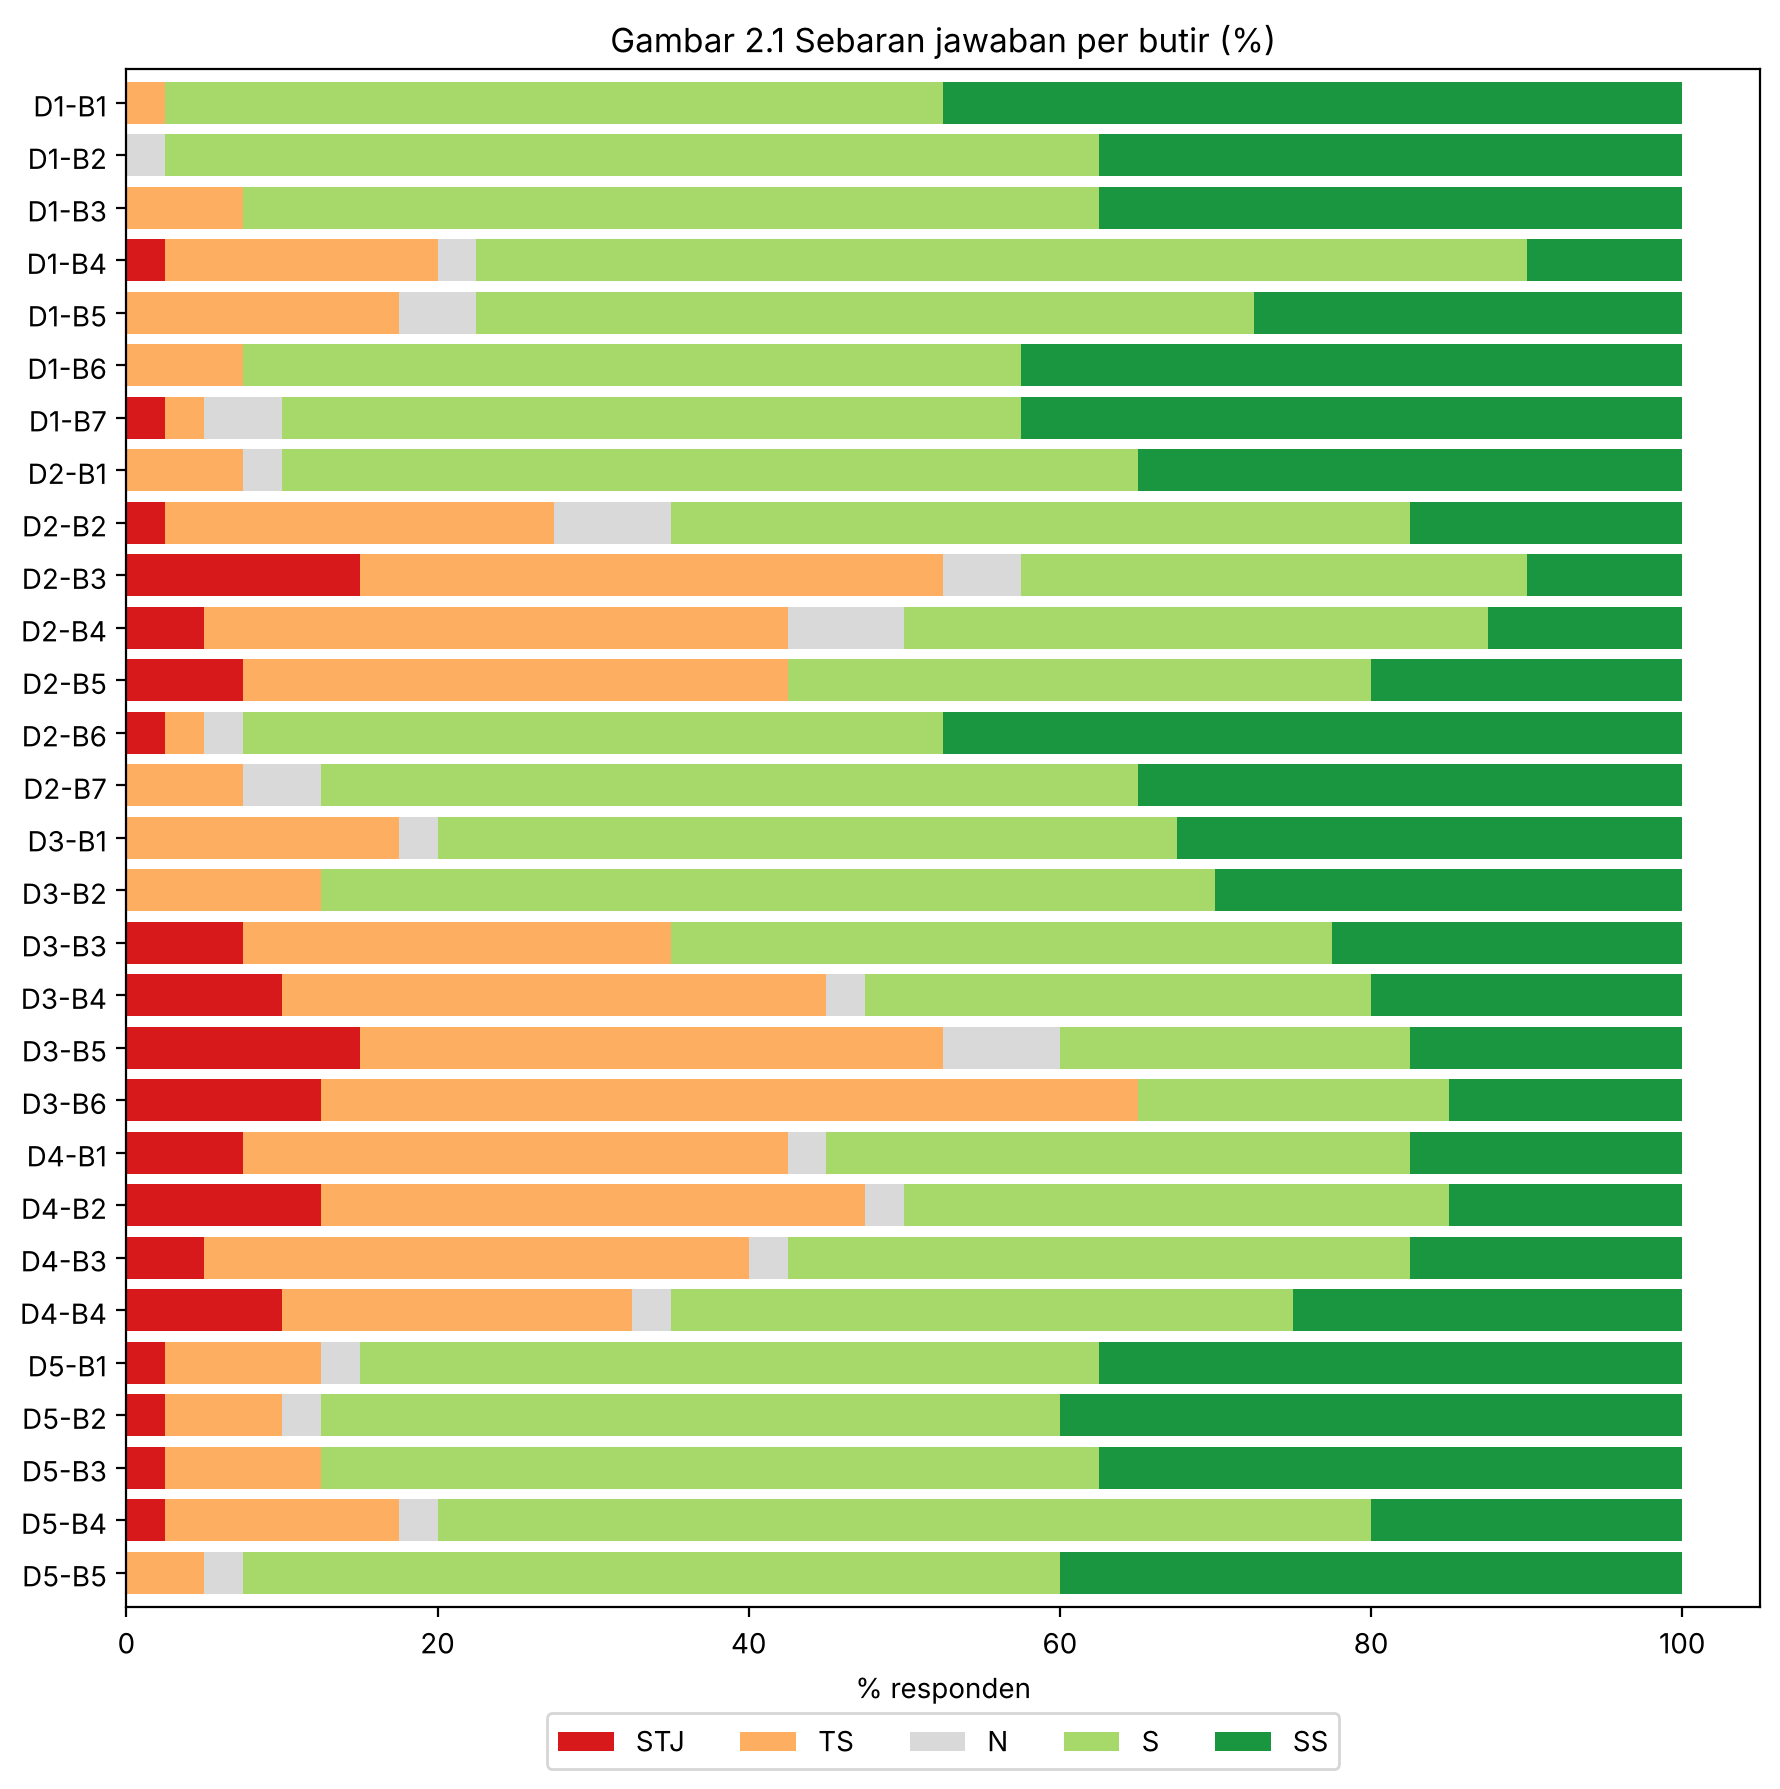


Persentase jawaban per butir (%):


,STJ,TS,N,S,SS
D1-B1,0.0,2.5,0.0,50.0,47.5
D1-B2,0.0,0.0,2.5,60.0,37.5
D1-B3,0.0,7.5,0.0,55.0,37.5
D1-B4,2.5,17.5,2.5,67.5,10.0
D1-B5,0.0,17.5,5.0,50.0,27.5
D1-B6,0.0,7.5,0.0,50.0,42.5
D1-B7,2.5,2.5,5.0,47.5,42.5
D2-B1,0.0,7.5,2.5,55.0,35.0
D2-B2,2.5,25.0,7.5,47.5,17.5
D2-B3,15.0,37.5,5.0,32.5,10.0


In [8]:
import matplotlib.pyplot as plt

kode_dim = {d: f"D{i}" for i, d in enumerate(dimensi, 1)}   # D1, D2, ... (keterangan dicetak di bawah)
for d, k in kode_dim.items():
    print(k, "=", d)

# Sebaran jawaban per butir (% responden)
nama_butir = [f"{kode_dim[d]}-{LABEL[k]}" for d, daftar in dimensi.items() for k in daftar]
urut_kolom = [k for daftar in dimensi.values() for k in daftar]
persen = pd.DataFrame({nb: num[k].value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0) * 100
                       for nb, k in zip(nama_butir, urut_kolom)}).T
persen.columns = ["STJ", "TS", "N", "S", "SS"]

fig, ax = plt.subplots(figsize=(9, 9))
persen.iloc[::-1].plot.barh(stacked=True, ax=ax, width=0.8,
                            color=["#d7191c", "#fdae61", "#d9d9d9", "#a6d96a", "#1a9641"])
ax.set_title("Gambar 2.1 Sebaran jawaban per butir (%)")
ax.set_xlabel("% responden")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

print("\nPersentase jawaban per butir (%):")
display(persen.round(1))

## Langkah 9: Visualisasi 2: sebaran skor rata-rata responden per dimensi

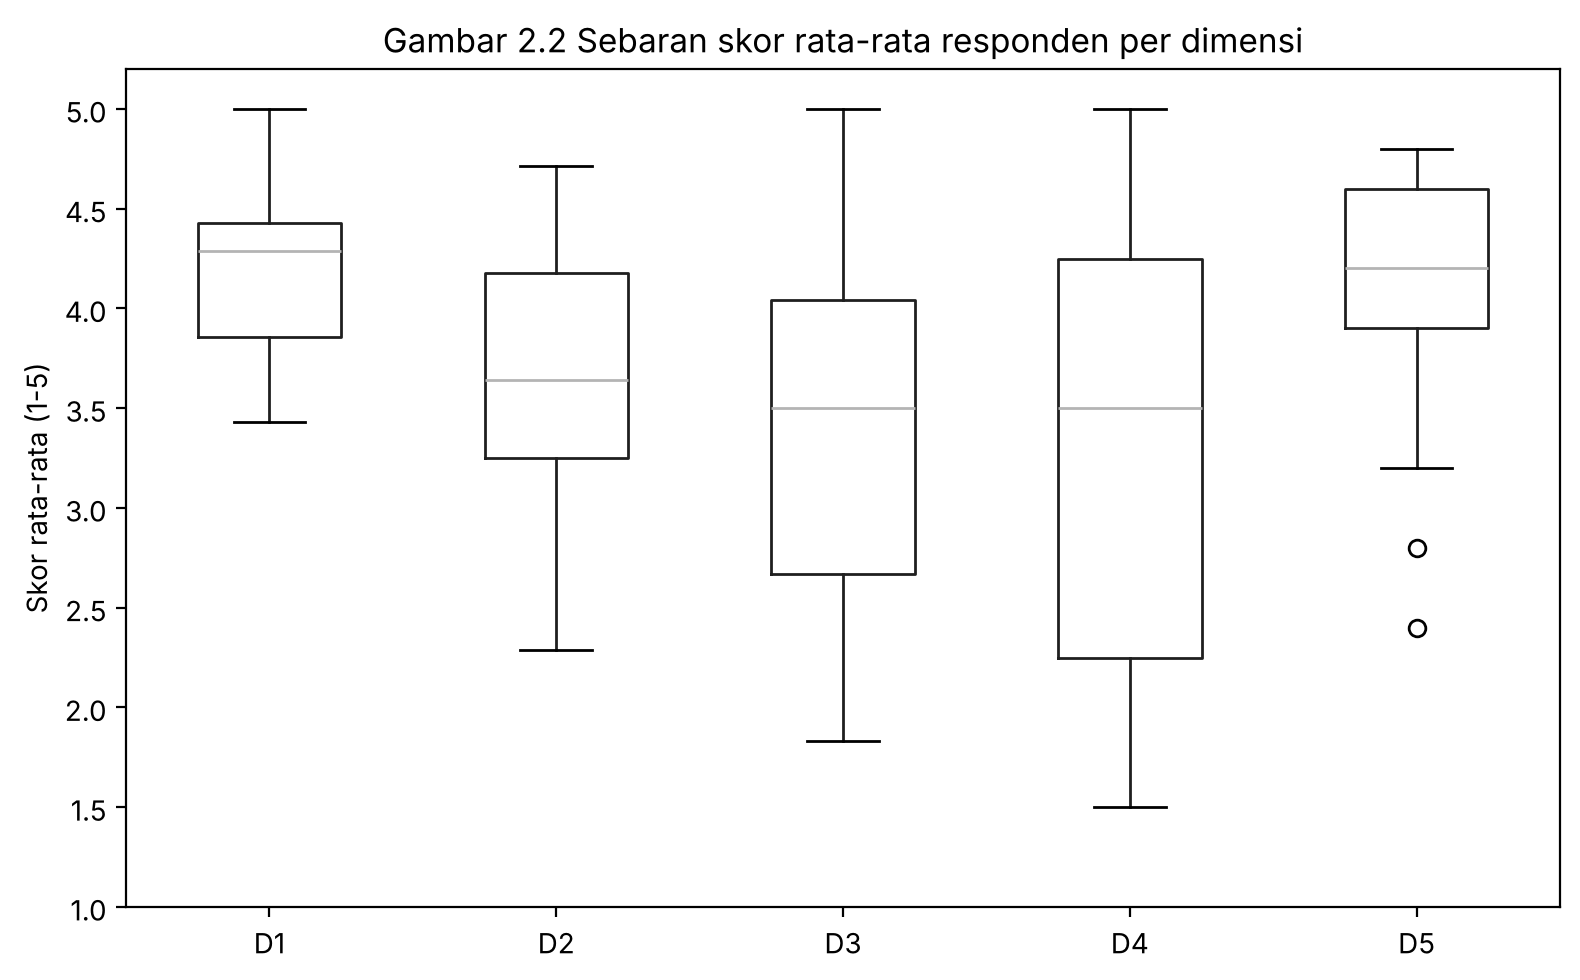

Statistik deskriptif skor rata-rata per dimensi:


,D1,D2,D3,D4,D5
count,40.00,40.00,40.00,40.00,40.00
mean,4.15,3.64,3.38,3.26,4.08
std,0.43,0.64,0.89,1.12,0.58
min,3.43,2.29,1.83,1.50,2.40
25%,3.86,3.25,2.67,2.25,3.90
50%,4.29,3.64,3.50,3.50,4.20
75%,4.43,4.18,4.04,4.25,4.60
max,5.00,4.71,5.00,5.00,4.80


In [9]:
# Sebaran skor rata-rata responden per dimensi (skala 1-5)
rata = pd.DataFrame({kode_dim[d]: num[daftar].mean(axis=1) for d, daftar in dimensi.items()})

fig, ax = plt.subplots(figsize=(8, 5))
rata.boxplot(ax=ax, grid=False)
ax.set_title("Gambar 2.2 Sebaran skor rata-rata responden per dimensi")
ax.set_ylabel("Skor rata-rata (1-5)")
ax.set_ylim(1, 5.2)
plt.tight_layout()
plt.show()

print("Statistik deskriptif skor rata-rata per dimensi:")
display(rata.describe().round(2))

## Langkah 10: Fungsi uji validitas dan reliabilitas + Pedoman Pengambilan Keputusan (dipakai berulang)

In [10]:
ALPHA_SIG       = 0.05   # taraf signifikansi uji r
BATAS_ALPHA     = 0.70   # α dimensi minimal
BATAS_CORRECTED = 0.30   # kriteria alternatif: corrected item-total r ≥ 0,30

def r_tabel_dari_n(n, alpha=ALPHA_SIG):
    """r tabel (dua sisi) dari n: r = t / sqrt(df + t²), df = n - 2."""
    t = stats.t.ppf(1 - alpha / 2, n - 2)
    return t / np.sqrt((n - 2) + t**2)

n = len(num)
r_tabel = r_tabel_dari_n(n)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

# ---- Pedoman 6: tindak lanjut per butir ----
def keputusan(valid, a_hapus, a_dim):
    if pd.isna(a_hapus):
        return "Pertahankan" if valid else "Tinjau ulang (dimensi ≤ 2 butir)"
    lebih_tinggi = a_hapus > a_dim
    if valid and not lebih_tinggi:
        return "Pertahankan"
    if not valid and lebih_tinggi:
        return "Buang atau revisi redaksi, lalu uji ulang"
    if valid and lebih_tinggi:
        return "Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)"
    return "Tinjau ulang sebelum dibuang; pertimbangkan validitas isi"

# ---- Pedoman 6: tindak lanjut per dimensi ----
def tindak_lanjut_dimensi(a_dim):
    if a_dim < BATAS_ALPHA:
        return "Periksa butir bermasalah, tambah butir yang relevan, atau perbaiki redaksi"
    return "Memenuhi kriteria (α ≥ 0,70)"

def uji(dims, data=None):
    """Uji validitas (r hitung vs r tabel, corrected r) dan reliabilitas per dimensi.
    data=None -> memakai seluruh responden (num); isi data lain untuk subset/sampel ulang."""
    data = num if data is None else data
    r_tab = r_tabel_dari_n(len(data))
    validitas, reliabilitas = [], []
    for nama, daftar in dims.items():
        x = data[daftar]
        total = x.sum(axis=1)
        a_dim = cronbach_alpha(x)
        reliabilitas.append({"Dimensi": nama, "Jumlah butir": len(daftar),
                             "Cronbach's alpha": round(a_dim, 3), "Kategori": kategori(a_dim),
                             "Tindak lanjut": tindak_lanjut_dimensi(a_dim)})
        for kolom in daftar:
            r, p = stats.pearsonr(x[kolom], total)
            r_kor, _ = stats.pearsonr(x[kolom], total - x[kolom])
            a_hapus = cronbach_alpha(x.drop(columns=kolom)) if len(daftar) > 2 else np.nan
            valid = bool(r > r_tab)
            validitas.append({
                "Dimensi": nama, "Butir": LABEL[kolom],
                "r hitung": round(r, 3), "r tabel": round(r_tab, 3),
                "Corrected r": round(r_kor, 3), "p-value": round(p, 4),
                "Keterangan": "Valid" if valid else "Tidak valid",
                "Alpha dimensi": round(a_dim, 3),
                "Alpha jika dihapus": round(a_hapus, 3) if pd.notna(a_hapus) else np.nan,
                "Keputusan": keputusan(valid, a_hapus, a_dim),
                "Pernyataan": kolom.split("[", 1)[1].rstrip("]").strip() if "[" in kolom else kolom,
            })
    return pd.DataFrame(validitas), pd.DataFrame(reliabilitas)
print("Fungsi siap.")

n = 40 | r tabel (α=0,05; df=38) = 0.312
Fungsi siap.


## Langkah 11: Uji validitas kelompok Penggunaan AI

In [11]:
val_ai, rel_ai = uji(kelompok["Penggunaan AI"])
kolom_validitas = ["Dimensi", "Butir", "r hitung", "r tabel", "Corrected r", "p-value", "Keterangan", "Pernyataan"]
display(val_ai[kolom_validitas])

,Dimensi,Butir,r hitung,r tabel,Corrected r,p-value,Keterangan,Pernyataan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.419,0.312,0.222,0.0071,Valid,Saya menggunakan platform AI hampir setiap kali mendapat...
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.390,0.312,0.224,0.0129,Valid,Saya menggunakan AI untuk mencari solusi atas permasalah...
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.626,0.312,0.418,0.0000,Valid,Saya menggunakan AI untuk mencari ide atau inspirasi dal...
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.506,0.312,0.205,0.0009,Valid,Saya merasa kesulitan memulai mengerjakan tugas tanpa ba...
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.793,0.312,0.597,0.0000,Valid,Saya merasa kurang yakin dengan hasil tugas apabila tida...
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.634,0.312,0.424,0.0000,Valid,Saya percaya bahwa AI dapat memberikan informasi yang me...
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,0.312,-0.061,0.1510,Tidak valid,Saya memeriksa kembali kebenaran informasi yang diberika...


## Langkah 12: Uji reliabilitas kelompok Penggunaan AI

In [12]:
kolom_alpha = ["Dimensi", "Butir", "Alpha dimensi", "Alpha jika dihapus", "Keputusan"]
display(rel_ai)
display(val_ai[kolom_alpha])

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori,Tindak lanjut
0,Penggunaan AI pada tugas atau projek kuliah,7,0.55,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."


,Dimensi,Butir,Alpha dimensi,Alpha jika dihapus,Keputusan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.55,0.531,Pertahankan
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.55,0.533,Pertahankan
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.55,0.456,Pertahankan
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.55,0.547,Pertahankan
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.55,0.341,Pertahankan
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.55,0.453,Pertahankan
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.55,0.639,"Buang atau revisi redaksi, lalu uji ulang"


## Langkah 13: Uji validitas kelompok Aspek Psikologis

In [13]:
val_psi, rel_psi = uji(kelompok["Aspek Psikologis"])
display(val_psi[kolom_validitas])

,Dimensi,Butir,r hitung,r tabel,Corrected r,p-value,Keterangan,Pernyataan
0,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B1,0.578,0.312,0.437,0.0001,Valid,Saya merasa perlu menggunakan AI setiap kali mendapatkan...
1,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B2,0.708,0.312,0.541,0.0000,Valid,aya merasa kesulitan menyelesaikan tugas kuliah apabila ...
2,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B3,0.804,0.312,0.651,0.0000,Valid,Saya cenderung mengikuti saran atau jawaban AI tanpa ban...
3,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B4,0.675,0.312,0.481,0.0000,Valid,Saya lebih sering menggunakan pemikiran atau jawaban yan...
4,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B5,0.797,0.312,0.636,0.0000,Valid,Saya merasa cemas ketika tidak dapat mengakses AI saat s...
5,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B6,0.389,0.312,0.208,0.0132,Valid,Penggunaan AI membuat saya lebih tertarik untuk mempelaj...
6,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B7,-0.094,0.312,-0.272,0.5625,Tidak valid,Saya tetap merasa yakin terhadap kemampuan diri sendiri ...
7,Kebiasaan penggunaan teknologi digital,B1,0.551,0.312,0.392,0.0002,Valid,Saya sering mengerjakan tugas kuliah sambil melakukan ak...
8,Kebiasaan penggunaan teknologi digital,B2,0.567,0.312,0.434,0.0001,Valid,Saya sering memeriksa notifikasi smartphone meskipun sed...
9,Kebiasaan penggunaan teknologi digital,B3,0.819,0.312,0.706,0.0000,Valid,Saya sering menunda pengerjaan tugas karena lebih tertar...


## Langkah 14: Uji reliabilitas kelompok Aspek Psikologis

In [14]:
display(rel_psi)
display(val_psi[kolom_alpha])

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori,Tindak lanjut
0,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,7,0.678,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."
1,Kebiasaan penggunaan teknologi digital,6,0.808,Baik,"Memenuhi kriteria (α ≥ 0,70)"
2,Prokrastinasi akademik,4,0.865,Baik,"Memenuhi kriteria (α ≥ 0,70)"
3,Respon emosional,5,0.555,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."


,Dimensi,Butir,Alpha dimensi,Alpha jika dihapus,Keputusan
0,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B1,0.678,0.637,Pertahankan
1,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B2,0.678,0.597,Pertahankan
2,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B3,0.678,0.550,Pertahankan
3,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B4,0.678,0.614,Pertahankan
4,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B5,0.678,0.555,Pertahankan
5,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B6,0.678,0.684,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)
6,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B7,0.678,0.769,"Buang atau revisi redaksi, lalu uji ulang"
7,Kebiasaan penggunaan teknologi digital,B1,0.808,0.812,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)
8,Kebiasaan penggunaan teknologi digital,B2,0.808,0.805,Pertahankan
9,Kebiasaan penggunaan teknologi digital,B3,0.808,0.744,Pertahankan


## Langkah 15: Ringkasan

In [15]:
ringkas = []
for g, v, r in [("Penggunaan AI", val_ai, rel_ai), ("Aspek Psikologis", val_psi, rel_psi)]:
    for _, d in r.iterrows():
        sub = v[v["Dimensi"] == d["Dimensi"]]
        ringkas.append({
            "Kelompok": g, "Dimensi": d["Dimensi"], "Butir": d["Jumlah butir"],
            "Valid": int((sub["Keterangan"] == "Valid").sum()),
            "Tidak valid": int((sub["Keterangan"] == "Tidak valid").sum()),
            "Valid jika corrected r ≥ 0,30": int((sub["Corrected r"] >= BATAS_CORRECTED).sum()),
            "Alpha": d["Cronbach's alpha"], "Kategori alpha": d["Kategori"],
            "Tindak lanjut dimensi": d["Tindak lanjut"],
        })
tabel_ringkas = pd.DataFrame(ringkas)
tabel_ringkas

,Kelompok,Dimensi,Butir,Valid,Tidak valid,"Valid jika corrected r ≥ 0,30",Alpha,Kategori alpha,Tindak lanjut dimensi
0,Penggunaan AI,Penggunaan AI pada tugas atau projek kuliah,7,6,1,3,0.550,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."
1,Aspek Psikologis,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,7,6,1,5,0.678,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."
2,Aspek Psikologis,Kebiasaan penggunaan teknologi digital,6,6,0,6,0.808,Baik,"Memenuhi kriteria (α ≥ 0,70)"
3,Aspek Psikologis,Prokrastinasi akademik,4,4,0,4,0.865,Baik,"Memenuhi kriteria (α ≥ 0,70)"
4,Aspek Psikologis,Respon emosional,5,5,0,3,0.555,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."


## Langkah 16: Penerapan Pedoman Pengambilan Keputusan (Butir 6)
Tiap butir diberi tindak lanjut berdasarkan kombinasi **validitas** (r hitung > r tabel) dan **alpha jika butir dihapus** dibandingkan **α dimensi**. Dimensi dengan α < 0,70 diberi tindak lanjut tersendiri.

| Kondisi butir | Tindak lanjut |
|---|---|
| Valid dan alpha jika dihapus **lebih rendah** dari α dimensi | Pertahankan |
| Tidak valid dan alpha jika dihapus **lebih tinggi** dari α dimensi | Buang atau revisi redaksi, lalu uji ulang |
| Valid, tetapi alpha jika dihapus **lebih tinggi** dari α dimensi | Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk) |
| Tidak valid, tetapi alpha jika dihapus **lebih rendah** dari α dimensi | Tinjau ulang sebelum dibuang; pertimbangkan validitas isi |
| Dimensi dengan α < 0,70 | Periksa butir bermasalah, tambah butir yang relevan, atau perbaiki redaksi |

In [16]:
val_semua = pd.concat([val_ai, val_psi], ignore_index=True)
rel_semua = pd.concat([rel_ai, rel_psi], ignore_index=True)

print("Jumlah butir per tindak lanjut:")
print(val_semua["Keputusan"].value_counts().to_string())

kolom_tampil = ["Dimensi", "Butir", "r hitung", "r tabel", "Corrected r", "Keterangan",
                "Alpha dimensi", "Alpha jika dihapus", "Keputusan"]
print("\nButir yang tindak lanjutnya bukan 'Pertahankan':")
display(val_semua.loc[val_semua["Keputusan"] != "Pertahankan", kolom_tampil])

print("\nDimensi dengan α < 0,70:")
dim_lemah = rel_semua[rel_semua["Cronbach's alpha"] < BATAS_ALPHA]
display(dim_lemah if len(dim_lemah) else "Tidak ada, semua dimensi memenuhi α ≥ 0,70")

Jumlah butir per tindak lanjut:
Keputusan
Pertahankan                                                    23
Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)     4
Buang atau revisi redaksi, lalu uji ulang                       2

Butir yang tindak lanjutnya bukan 'Pertahankan':


,Dimensi,Butir,r hitung,r tabel,Corrected r,Keterangan,Alpha dimensi,Alpha jika dihapus,Keputusan
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,0.312,-0.061,Tidak valid,0.550,0.639,"Buang atau revisi redaksi, lalu uji ulang"
12,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B6,0.389,0.312,0.208,Valid,0.678,0.684,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)
13,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B7,-0.094,0.312,-0.272,Tidak valid,0.678,0.769,"Buang atau revisi redaksi, lalu uji ulang"
14,Kebiasaan penggunaan teknologi digital,B1,0.551,0.312,0.392,Valid,0.808,0.812,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)
23,Prokrastinasi akademik,B4,0.757,0.312,0.569,Valid,0.865,0.886,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)
27,Respon emosional,B4,0.413,0.312,0.065,Valid,0.555,0.644,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)



Dimensi dengan α < 0,70:


,Dimensi,Jumlah butir,Cronbach's alpha,Kategori,Tindak lanjut
0,Penggunaan AI pada tugas atau projek kuliah,7,0.550,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."
1,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,7,0.678,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."
4,Respon emosional,5,0.555,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."


## Langkah 17: Pengujian berulang (iteratif)
Setelah butir dibuang, analisis dijalankan ulang sampai tidak ada lagi butir dengan keputusan **"Buang atau revisi redaksi"**.
Aturan simulasi: tiap putaran hanya **satu butir** dibuang (yang r hitungnya paling rendah), dan dimensi tidak dikurangi hingga di bawah `MIN_BUTIR` butir.

> Catatan: pembuangan butir tidak boleh semata-mata mengejar angka. Hasil di bawah adalah **simulasi**; keputusan akhir tetap mempertimbangkan kecukupan cakupan isi instrumen.

In [17]:
MIN_BUTIR = 3   # jangan kurangi dimensi sampai di bawah ini

def uji_berulang(dims_awal, data=None, min_butir=MIN_BUTIR, maks_putaran=20):
    data = num if data is None else data
    dims = {k: list(v) for k, v in dims_awal.items()}
    log = []
    for putaran in range(1, maks_putaran + 1):
        val, rel = uji(dims, data)
        kandidat = val[val["Keputusan"].str.startswith("Buang")]
        kandidat = kandidat[kandidat["Dimensi"].map(lambda d: len(dims[d])) > min_butir]
        if kandidat.empty:
            break
        terburuk = kandidat.sort_values("r hitung").iloc[0]
        a_awal = rel.loc[rel["Dimensi"] == terburuk["Dimensi"], "Cronbach's alpha"].iloc[0]
        dims[terburuk["Dimensi"]].remove(KOLOM_DARI[(terburuk["Dimensi"], terburuk["Butir"])])
        a_baru = cronbach_alpha(data[dims[terburuk["Dimensi"]]])
        log.append({"Putaran": putaran, "Dimensi": terburuk["Dimensi"], "Butir dibuang": terburuk["Butir"],
                    "r hitung": terburuk["r hitung"], "α sebelum": a_awal, "α sesudah": round(a_baru, 3)})
    val, rel = uji(dims, data)
    return dims, val, rel, pd.DataFrame(log)

dims_akhir, val_akhir, rel_akhir, log_iterasi = uji_berulang(dimensi)

print("Riwayat pembuangan butir:")
display(log_iterasi if len(log_iterasi) else "Tidak ada butir yang perlu dibuang menurut aturan simulasi.")

print("\nReliabilitas dimensi setelah iterasi:")
display(rel_akhir)

sisa = val_akhir[val_akhir["Keputusan"] != "Pertahankan"]
print("\nButir yang masih perlu ditinjau manual setelah iterasi:")
display(sisa[kolom_tampil] if len(sisa) else "Tidak ada")

Riwayat pembuangan butir:


,Putaran,Dimensi,Butir dibuang,r hitung,α sebelum,α sesudah
0,1,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B7,-0.094,0.678,0.769
1,2,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,0.550,0.639



Reliabilitas dimensi setelah iterasi:


,Dimensi,Jumlah butir,Cronbach's alpha,Kategori,Tindak lanjut
0,Penggunaan AI pada tugas atau projek kuliah,6,0.639,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."
1,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,6,0.769,Reliabel,"Memenuhi kriteria (α ≥ 0,70)"
2,Kebiasaan penggunaan teknologi digital,6,0.808,Baik,"Memenuhi kriteria (α ≥ 0,70)"
3,Prokrastinasi akademik,4,0.865,Baik,"Memenuhi kriteria (α ≥ 0,70)"
4,Respon emosional,5,0.555,Tidak reliabel,"Periksa butir bermasalah, tambah butir yang relevan, ata..."



Butir yang masih perlu ditinjau manual setelah iterasi:


,Dimensi,Butir,r hitung,r tabel,Corrected r,Keterangan,Alpha dimensi,Alpha jika dihapus,Keputusan
11,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B6,0.421,0.312,0.250,Valid,0.769,0.788,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)
12,Kebiasaan penggunaan teknologi digital,B1,0.551,0.312,0.392,Valid,0.808,0.812,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)
21,Prokrastinasi akademik,B4,0.757,0.312,0.569,Valid,0.865,0.886,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)
25,Respon emosional,B4,0.413,0.312,0.065,Valid,0.555,0.644,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)


## Langkah 18: Latihan 1: Interpretasi
Sebutkan butir yang **tidak valid** beserta r hitung dan r tabelnya, lalu jelaskan dugaan penyebabnya.
Tabel di bawah juga memuat statistik jawaban (rata-rata, SD, modus) sebagai bahan menyusun dugaan penyebab.

In [18]:
tdk_valid = val_semua[val_semua["Keterangan"] == "Tidak valid"].copy()

if tdk_valid.empty:
    print("Semua butir valid.")
else:
    def stat_butir(row):
        x = num[KOLOM_DARI[(row["Dimensi"], row["Butir"])]]
        modus = int(x.mode().iloc[0])
        return pd.Series({"Rata-rata": round(x.mean(), 2), "SD": round(x.std(ddof=1), 2),
                          "Modus": modus, "% menjawab modus": round((x == modus).mean() * 100)})

    def dugaan(row):
        sebab = []
        if row["Corrected r"] < 0:
            sebab.append("korelasi negatif dengan butir lain (arah butir berlawanan atau konstruk berbeda)")
        elif row["Corrected r"] < BATAS_CORRECTED:
            sebab.append("korelasi dengan butir lain lemah (redaksi ambigu atau aspek berbeda)")
        if row["SD"] < 0.60 or row["% menjawab modus"] >= 75:
            sebab.append("variasi jawaban rendah (hampir semua responden menjawab sama)")
        sebab.append(f"n = {n} relatif kecil sehingga r tidak stabil")
        return ", ".join(sebab)

    lat1 = pd.concat([tdk_valid[["Dimensi", "Butir", "r hitung", "r tabel", "Corrected r", "Pernyataan"]],
                      tdk_valid.apply(stat_butir, axis=1)], axis=1)
    lat1["Dugaan penyebab"] = lat1.apply(dugaan, axis=1)
    print(f"Butir tidak valid: {len(lat1)} dari {len(val_semua)} butir (r tabel = {r_tabel:.3f})")
    display(lat1)

Butir tidak valid: 2 dari 29 butir (r tabel = 0.312)


,Dimensi,Butir,r hitung,r tabel,Corrected r,Pernyataan,Rata-rata,SD,Modus,% menjawab modus,Dugaan penyebab
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,0.312,-0.061,Saya memeriksa kembali kebenaran informasi yang diberika...,4.25,0.87,4.0,48.0,korelasi negatif dengan butir lain (arah butir berlawana...
13,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B7,-0.094,0.312,-0.272,Saya tetap merasa yakin terhadap kemampuan diri sendiri ...,4.15,0.83,4.0,52.0,korelasi negatif dengan butir lain (arah butir berlawana...


## Langkah 19: Latihan 2: Perbandingan kriteria
Berapa butir valid jika memakai **r hitung > r tabel**, dibandingkan memakai **corrected r ≥ 0,30**? Jelaskan selisihnya.

In [19]:
bandingkan = val_semua.assign(
    valid_r=val_semua["r hitung"] > val_semua["r tabel"],
    valid_corr=val_semua["Corrected r"] >= BATAS_CORRECTED)

lat2 = (bandingkan.groupby("Dimensi", sort=False)
        .agg(**{"Jumlah butir": ("Butir", "count"),
                "Valid (r hitung > r tabel)": ("valid_r", "sum"),
                "Valid (corrected r ≥ 0,30)": ("valid_corr", "sum")}))
lat2.loc["TOTAL"] = lat2.sum()
lat2["Selisih"] = lat2["Valid (r hitung > r tabel)"] - lat2["Valid (corrected r ≥ 0,30)"]
display(lat2.astype(int))

beda = bandingkan[bandingkan["valid_r"] != bandingkan["valid_corr"]]
print("\nButir yang statusnya berbeda antar kriteria:")
display(beda[["Dimensi", "Butir", "r hitung", "Corrected r", "valid_r", "valid_corr"]]
        .rename(columns={"valid_r": "Valid (r hitung)", "valid_corr": "Valid (corrected r)"})
        if len(beda) else "Tidak ada perbedaan")

print("""Penjelasan selisih:
- r hitung menghubungkan butir dengan skor total yang MENGANDUNG butir itu sendiri, sehingga korelasinya
  terdongkrak (part-whole overlap), terutama pada dimensi dengan sedikit butir.
- corrected r menghubungkan butir dengan skor total TANPA butir itu, sehingga lebih ketat/jujur.
- Ambang corrected r ≥ 0,30 bersifat tetap, sedangkan r tabel bergantung pada n (n kecil -> r tabel besar).""")

,Jumlah butir,Valid (r hitung > r tabel),"Valid (corrected r ≥ 0,30)",Selisih
Dimensi,,,,
Penggunaan AI pada tugas atau projek kuliah,7,6,3,3
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,7,6,5,1
Kebiasaan penggunaan teknologi digital,6,6,6,0
Prokrastinasi akademik,4,4,4,0
Respon emosional,5,5,3,2
TOTAL,29,27,21,6



Butir yang statusnya berbeda antar kriteria:


,Dimensi,Butir,r hitung,Corrected r,Valid (r hitung),Valid (corrected r)
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.419,0.222,True,False
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.390,0.224,True,False
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.506,0.205,True,False
12,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B6,0.389,0.208,True,False
25,Respon emosional,B2,0.590,0.297,True,False
27,Respon emosional,B4,0.413,0.065,True,False


Penjelasan selisih:
- r hitung menghubungkan butir dengan skor total yang MENGANDUNG butir itu sendiri, sehingga korelasinya
  terdongkrak (part-whole overlap), terutama pada dimensi dengan sedikit butir.
- corrected r menghubungkan butir dengan skor total TANPA butir itu, sehingga lebih ketat/jujur.
- Ambang corrected r ≥ 0,30 bersifat tetap, sedangkan r tabel bergantung pada n (n kecil -> r tabel besar).


## Langkah 20: Latihan 3: Perbaikan instrumen
Buang **satu** butir yang tidak valid, jalankan ulang analisis, dan bandingkan α dimensi sebelum dan sesudah.
Isi `BUTIR_DIBUANG` dengan pasangan `("nama dimensi", "B#")`, atau biarkan `None` agar dipilih otomatis (butir tidak valid dengan r hitung terendah).

In [20]:
BUTIR_DIBUANG = None    # contoh: ("Respon emosional", "B4")

if BUTIR_DIBUANG is None:
    pilih = val_semua[val_semua["Keterangan"] == "Tidak valid"].sort_values("r hitung")
    BUTIR_DIBUANG = (pilih.iloc[0]["Dimensi"], pilih.iloc[0]["Butir"]) if len(pilih) else None

if BUTIR_DIBUANG is None:
    print("Tidak ada butir tidak valid yang bisa dibuang.")
else:
    dim_t, lbl_t = BUTIR_DIBUANG
    kolom_buang = KOLOM_DARI[(dim_t, lbl_t)]
    daftar_baru = [k for k in dimensi[dim_t] if k != kolom_buang]

    print(f"Butir dibuang : {dim_t} / {lbl_t}")
    print(f"Pernyataan    : {kolom_buang.split('[', 1)[1].rstrip(']').strip()}\n")

    val_sblm, rel_sblm = uji({dim_t: dimensi[dim_t]})
    val_ssdh, rel_ssdh = uji({dim_t: daftar_baru})

    a0 = rel_sblm["Cronbach's alpha"].iloc[0]
    a1 = rel_ssdh["Cronbach's alpha"].iloc[0]
    lat3 = pd.DataFrame({
        "Dimensi": [dim_t],
        "Butir sebelum": [len(dimensi[dim_t])], "Butir sesudah": [len(daftar_baru)],
        "α sebelum": [a0], "α sesudah": [a1], "Perubahan α": [round(a1 - a0, 3)],
        "Kategori sebelum": [kategori(a0)], "Kategori sesudah": [kategori(a1)],
        "Tidak valid sebelum": [int((val_sblm["Keterangan"] == "Tidak valid").sum())],
        "Tidak valid sesudah": [int((val_ssdh["Keterangan"] == "Tidak valid").sum())],
    })
    display(lat3)

    print("Uji validitas ulang setelah butir dibuang:")
    display(val_ssdh[kolom_tampil])
    print("""Catatan: jika α naik tetapi butir yang dibuang penting bagi cakupan isi dimensi,
pertimbangkan merevisi redaksi butir, bukan membuangnya.""")

Butir dibuang : Aspek Psikologis penggunaan AI pada tugas atau projek kuliah / B7
Pernyataan    : Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah.



,Dimensi,Butir sebelum,Butir sesudah,α sebelum,α sesudah,Perubahan α,Kategori sebelum,Kategori sesudah,Tidak valid sebelum,Tidak valid sesudah
0,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,7,6,0.678,0.769,0.091,Tidak reliabel,Reliabel,1,0


Uji validitas ulang setelah butir dibuang:


,Dimensi,Butir,r hitung,r tabel,Corrected r,Keterangan,Alpha dimensi,Alpha jika dihapus,Keputusan
0,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B1,0.607,0.312,0.477,Valid,0.769,0.749,Pertahankan
1,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B2,0.739,0.312,0.591,Valid,0.769,0.715,Pertahankan
2,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B3,0.790,0.312,0.637,Valid,0.769,0.700,Pertahankan
3,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B4,0.657,0.312,0.464,Valid,0.769,0.749,Pertahankan
4,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B5,0.819,0.312,0.678,Valid,0.769,0.686,Pertahankan
5,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B6,0.421,0.312,0.250,Valid,0.769,0.788,Tinjau isi butir (kemungkinan ambigu atau berbeda konstruk)


Catatan: jika α naik tetapi butir yang dibuang penting bagi cakupan isi dimensi,
pertimbangkan merevisi redaksi butir, bukan membuangnya.


## Langkah 21: Latihan 4: Pengaruh ukuran sampel
Ubah n dengan mengambil subset acak (misalnya `num.sample(20, random_state=1)`), lalu amati perubahan **r tabel** dan **jumlah butir valid**.

In [21]:
UKURAN = [10, 15, 20, 30, len(num)]   # n terakhir = seluruh responden
baris = []
for m in UKURAN:
    sub = num if m >= len(num) else num.sample(m, random_state=1)
    v, r = uji(dimensi, sub)
    baris.append({"n": len(sub), "df": len(sub) - 2, "r tabel": round(r_tabel_dari_n(len(sub)), 3),
                  "Butir valid (r hitung)": int((v["Keterangan"] == "Valid").sum()),
                  "Butir valid (corrected r ≥ 0,30)": int((v["Corrected r"] >= BATAS_CORRECTED).sum()),
                  "Total butir": len(v),
                  "Dimensi α ≥ 0,70": int((r["Cronbach's alpha"] >= BATAS_ALPHA).sum())})
lat4 = pd.DataFrame(baris)
display(lat4)

# detail per butir: seluruh responden vs sampel 20 responden (contoh dari modul)
sub20 = num.sample(20, random_state=1)
v_all, _ = uji(dimensi)
v_20, _ = uji(dimensi, sub20)
detail = v_all[["Dimensi", "Butir", "r hitung", "Keterangan"]].merge(
    v_20[["Dimensi", "Butir", "r hitung", "r tabel", "Keterangan"]],
    on=["Dimensi", "Butir"], suffixes=(f" (n={n})", " (n=20)"))
detail["Status berubah?"] = detail[f"Keterangan (n={n})"] != detail["Keterangan (n=20)"]
print(f"\nPerbandingan per butir: n={n} vs n=20 (random_state=1)")
display(detail)
print("Butir yang statusnya berubah:", int(detail["Status berubah?"].sum()), "dari", len(detail))
print("""\nPengamatan: makin kecil n, makin besar r tabel (butir harus berkorelasi lebih kuat agar dinyatakan valid),
sementara r hitung juga makin tidak stabil. Sampel kecil membuat kesimpulan validitas mudah berubah.""")

,n,df,r tabel,Butir valid (r hitung),"Butir valid (corrected r ≥ 0,30)",Total butir,"Dimensi α ≥ 0,70"
0,10,8,0.632,18,25,29,3
1,15,13,0.514,23,24,29,3
2,20,18,0.444,23,22,29,2
3,30,28,0.361,24,21,29,2
4,40,38,0.312,27,21,29,2



Perbandingan per butir: n=40 vs n=20 (random_state=1)


,Dimensi,Butir,r hitung (n=40),Keterangan (n=40),r hitung (n=20),r tabel,Keterangan (n=20),Status berubah?
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.419,Valid,0.369,0.444,Tidak valid,True
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.390,Valid,0.218,0.444,Tidak valid,True
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.626,Valid,0.520,0.444,Valid,False
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.506,Valid,0.688,0.444,Valid,False
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.793,Valid,0.784,0.444,Valid,False
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.634,Valid,0.638,0.444,Valid,False
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,Tidak valid,0.369,0.444,Tidak valid,False
7,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B1,0.578,Valid,0.555,0.444,Valid,False
8,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B2,0.708,Valid,0.761,0.444,Valid,False
9,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B3,0.804,Valid,0.765,0.444,Valid,False


Butir yang statusnya berubah: 4 dari 29

Pengamatan: makin kecil n, makin besar r tabel (butir harus berkorelasi lebih kuat agar dinyatakan valid),
sementara r hitung juga makin tidak stabil. Sampel kecil membuat kesimpulan validitas mudah berubah.


## Langkah 22: Latihan 5: Refleksi
**Mengapa instrumen yang reliabel belum tentu valid?**

Reliabilitas hanya menunjukkan **konsistensi** (butir-butir saling sejalan atau hasil stabil), sedangkan validitas menunjukkan **ketepatan** (apakah yang diukur benar-benar konstruk yang dimaksud). Contoh sederhana: timbangan yang selalu menunjukkan angka 3 kg lebih berat sangat konsisten (reliabel), tetapi hasilnya tidak tepat (tidak valid). Contoh instrumen: lima butir tentang "seberapa sering membuka media sosial" bisa sangat konsisten (α tinggi), tetapi tidak valid bila dipakai untuk mengukur "kecemasan akademik".

Simulasi di bawah memperlihatkan hal itu: butir-butir saling berkorelasi kuat (α tinggi) tetapi hampir tidak berkorelasi dengan konstruk target.

In [22]:
rng = np.random.default_rng(1)
m = 200
konstruk_terukur = rng.normal(size=m)   # yang SEBENARNYA diukur butir (mis. kebiasaan membuka media sosial)
konstruk_target  = rng.normal(size=m)   # yang INGIN diukur (mis. kecemasan akademik), tidak berhubungan

butir_sim = pd.DataFrame({f"S{i}": 0.9 * konstruk_terukur + 0.4 * rng.normal(size=m) for i in range(1, 6)})
a_sim = cronbach_alpha(butir_sim)
r_sim, _ = stats.pearsonr(butir_sim.sum(axis=1), konstruk_target)

print(f"Cronbach's alpha 5 butir          : {a_sim:.3f}  -> {kategori(a_sim)} (konsisten)")
print(f"Korelasi skor total dgn konstruk target: {r_sim:.3f}  -> hampir nol (tidak valid untuk konstruk target)")

Cronbach's alpha 5 butir          : 0.952  -> Sangat baik (konsisten)
Korelasi skor total dgn konstruk target: 0.005  -> hampir nol (tidak valid untuk konstruk target)


## Langkah 23: Simpan hasil ke Excel

In [23]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

nama_out = "hasil_uji_validitas_reliabilitas_3TIC.xlsx"
data_bersih = pd.concat([data_awal.reset_index(drop=True), num.reset_index(drop=True)], axis=1)

with pd.ExcelWriter(nama_out, engine="openpyxl") as w:
    tabel_ringkas.to_excel(w, sheet_name="Ringkasan", index=False)
    val_ai.to_excel(w, sheet_name="Validitas_AI", index=False)
    rel_ai.to_excel(w, sheet_name="Reliabilitas_AI", index=False)
    val_psi.to_excel(w, sheet_name="Validitas_Psikologis", index=False)
    rel_psi.to_excel(w, sheet_name="Reliabilitas_Psikologis", index=False)
    val_semua.to_excel(w, sheet_name="Keputusan_Butir", index=False)
    log_iterasi.to_excel(w, sheet_name="Iterasi_Pembuangan", index=False)
    if len(tdk_valid): lat1.to_excel(w, sheet_name="Latihan1_Interpretasi", index=False)
    lat2.reset_index().to_excel(w, sheet_name="Latihan2_Kriteria", index=False)
    if BUTIR_DIBUANG is not None: lat3.to_excel(w, sheet_name="Latihan3_Perbaikan", index=False)
    lat4.to_excel(w, sheet_name="Latihan4_Ukuran_Sampel", index=False)
    data_bersih.to_excel(w, sheet_name="Data_Bersih", index=False)
    for ws in w.book.worksheets:
        for cell in ws[1]:
            cell.font = Font(name="Arial", bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="305496")
            cell.alignment = Alignment(wrap_text=True, vertical="center")
        for row in ws.iter_rows(min_row=2):
            for cell in row: cell.font = Font(name="Arial")
        for i, col in enumerate(ws.columns, 1):
            if ws.title == "Data_Bersih":
                ws.column_dimensions[get_column_letter(i)].width = 14
            else:
                m = max(len(str(c.value)) if c.value is not None else 0 for c in col)
                ws.column_dimensions[get_column_letter(i)].width = min(max(12, m + 2), 40)
        ws.freeze_panes = "A2"

print("Tersimpan:", nama_out)
if IN_COLAB:
    files.download(nama_out)

Tersimpan: hasil_uji_validitas_reliabilitas_3TIC.xlsx
